Import and set up data

In [27]:
# !pip install pandas seaborn matplotlib
# install py -m pip install pandas seaborn matplotlib

In [28]:
import pandas as pd
import seaborn as sns

import matplotlib.pyplot as plt
import matplotlib.ticker as tic

sns.set_theme(style = "whitegrid")

df = pd.read_csv("../Data/transformed_study_data.csv")

Exploratory visualization #1

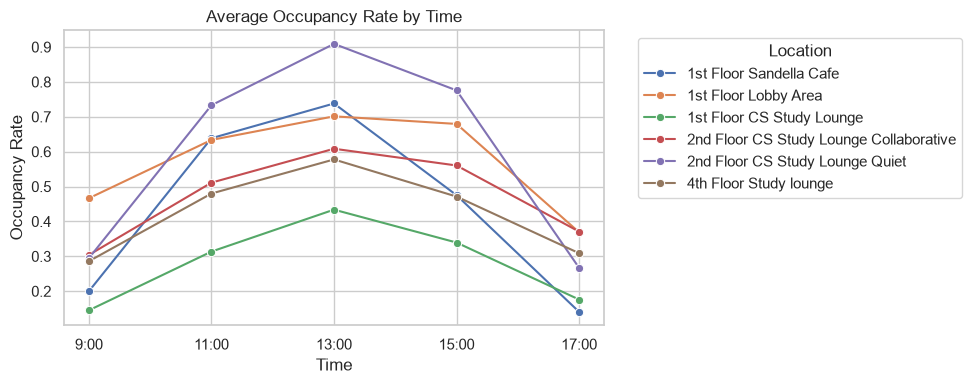

In [ ]:
occupancy_time = (
    df.groupby(["time", "location"])["occupancy_rate"]
      .mean()
      .reset_index()
)

# Time ordering
time_order = ["9:00", "11:00", "13:00", "15:00", "17:00"]
occupancy_time["time"] = pd.Categorical(
    occupancy_time["time"],
    categories=time_order,
    ordered=True
)

# Location ordering
location_order = [
    "1st Floor Sandella Cafe",
    "1st Floor Lobby Area",
    "1st Floor CS Study Lounge",
    "2nd Floor CS Study Lounge Collaborative",
    "2nd Floor CS Study Lounge Quiet",
    "4th Floor Study lounge"
]
occupancy_time["location"] = pd.Categorical(
    occupancy_time["location"],
    categories=location_order,
    ordered=True
)

# Sort by time and location
occupancy_time = occupancy_time.sort_values(["time", "location"])

# Plot
plt.figure(figsize=(10, 4))
sns.lineplot(
    data=occupancy_time,
    x="time",
    y="occupancy_rate",
    hue="location",
    marker="o"
)
plt.title("Average Occupancy Rate by Time")
plt.xlabel("Time")
plt.ylabel("Occupancy Rate")

# Move legend outside plot
plt.legend(
    title="Location",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

Exploratory Visualization #2

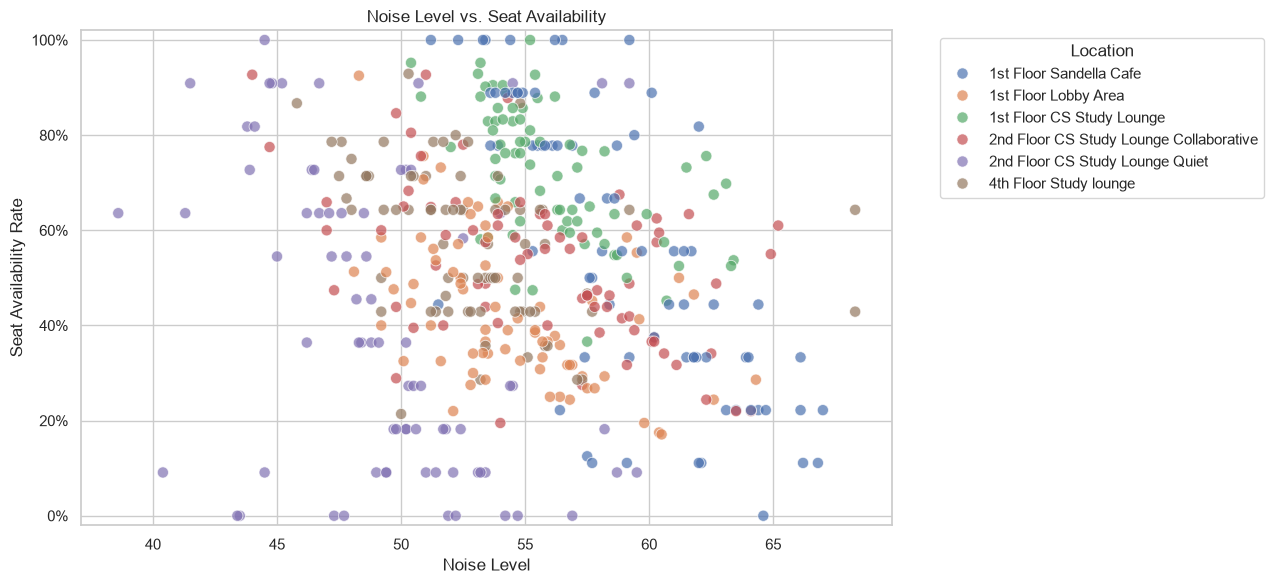

In [ ]:
# compare noise level with seat availability

# Set the order of study space locations
location_order = [
    "1st Floor Sandella Cafe",
    "1st Floor Lobby Area",
    "1st Floor CS Study Lounge",
    "2nd Floor CS Study Lounge Collaborative",
    "2nd Floor CS Study Lounge Quiet",
    "4th Floor Study lounge"
]

# Set the location order in the dataset
df["location"] = pd.Categorical(
    df["location"],
    categories=location_order,
    ordered=True
)

# Figure size
plt.figure(figsize=(13, 6))

# scatterplot
sns.scatterplot(
    data=df,
    x="noise_level",
    y="availability_rate",
    hue="location",
    hue_order=location_order,
    alpha=0.7,
    s=65
)

plt.title("Noise Level vs. Seat Availability")
plt.xlabel("Noise Level")
plt.ylabel("Seat Availability Rate")

# Format y-axis to percents
plt.gca().yaxis.set_major_formatter(
    tic.PercentFormatter(1.0)
)

# added padding (-0.02 to 1.02) so 0% and 100% points aren't cut off
plt.ylim(-0.02, 1.02)

# Move legend outside the plot
plt.legend(
    title="Location",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [25]:
# checking average total seats in regards to the note about seat availability in general

capacity_summary = df.groupby("location")[["capacity", "open_seats", "occupancy_rate"]].mean().reset_index()
print(capacity_summary)

# Proves seat capacity is a major confounding variable

                                  location   capacity  open_seats  \
0                  1st Floor Sandella Cafe   8.986667    5.066667   
1                     1st Floor Lobby Area  40.786667   17.533333   
2                1st Floor CS Study Lounge  41.573333   29.920000   
3  2nd Floor CS Study Lounge Collaborative  40.533333   21.440000   
4          2nd Floor CS Study Lounge Quiet  11.013333    4.453333   
5                   4th Floor Study lounge  14.000000    8.066667   

   occupancy_rate  
0        0.438440  
1        0.569933  
2        0.281573  
3        0.470920  
4        0.595867  
5        0.424693  


Exploratory Visualization #3

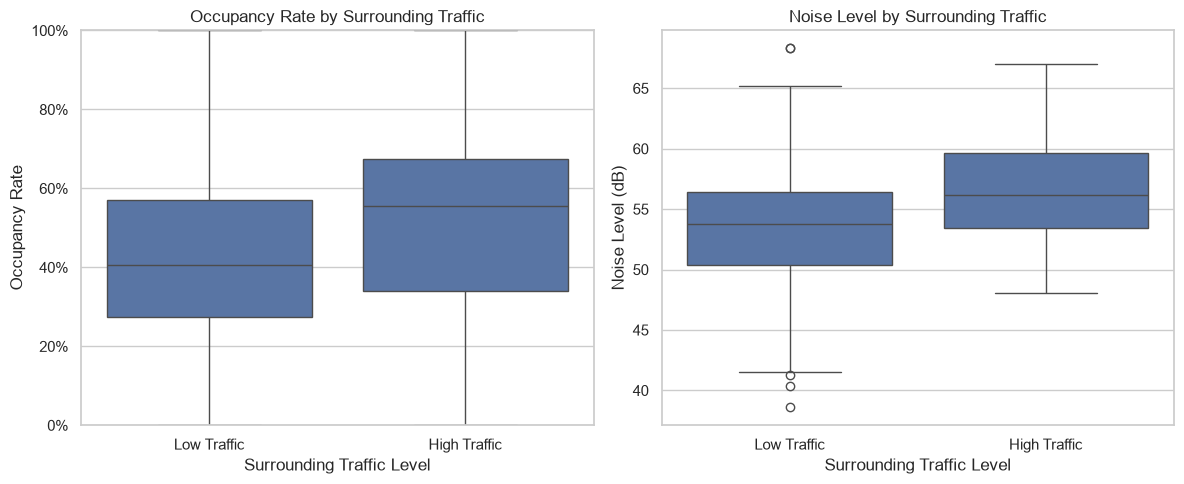

In [29]:
#  compare occupancy and noise by traffic level

# based off transformed study data csv
traffic_map = {
    "1st Floor Sandella Cafe": "High Traffic",
    "1st Floor Lobby Area": "High Traffic",
    "1st Floor CS Study Lounge": "Low Traffic",
    "2nd Floor CS Study Lounge Collaborative": "Low Traffic",
    "2nd Floor CS Study Lounge Quiet": "Low Traffic",
    "4th Floor Study lounge": "Low Traffic"
}

df["traffic_level"] = df["location"].map(traffic_map)

# 2 plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

traffic_order = ["Low Traffic", "High Traffic"]

# compare occupancy rates
sns.boxplot(
    data=df,
    x="traffic_level",
    y="occupancy_rate",
    order=traffic_order,
    ax=axes[0]
)

axes[0].set_title("Occupancy Rate by Surrounding Traffic")
axes[0].set_xlabel("Surrounding Traffic Level")
axes[0].set_ylabel("Occupancy Rate")
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[0].set_ylim(0, 1)

# compare noise levels
sns.boxplot(
    data=df,
    x="traffic_level",
    y="noise_level",
    order=traffic_order,
    ax=axes[1]
)

axes[1].set_title("Noise Level by Surrounding Traffic")
axes[1].set_xlabel("Surrounding Traffic Level")
axes[1].set_ylabel("Noise Level (dB)")

plt.tight_layout()
plt.show()